# Heart Disease Prediction Project

## 1. Executive Summary

This notebook details the development of a machine learning model to predict heart disease using the UCI Heart Disease dataset. The project encompasses data exploration, preprocessing, model training with various algorithms (Logistic Regression, Decision Tree, Random Forest, XGBoost), comprehensive evaluation, feature importance analysis, and SHAP explainability. The goal is to provide insights into factors contributing to heart disease and develop a reliable predictive tool for early diagnosis.

## 2. Problem Statement

Cardiovascular diseases are a leading cause of mortality worldwide. Early and accurate prediction of heart disease can significantly improve patient outcomes through timely intervention and lifestyle modifications. This project aims to build a robust predictive model that can identify individuals at high risk of heart disease based on clinical and demographic features, thereby assisting healthcare professionals in risk assessment and patient management.

## 3. Dataset Overview

The dataset used is the Heart Disease UCI dataset, commonly available from platforms like Kaggle or the UCI Machine Learning Repository. It contains medical records of patients, including various attributes that are potentially indicative of heart disease. The target variable indicates the presence or absence of heart disease.

In [1]:
# Install necessary libraries if not already installed
!pip install pandas scikit-learn matplotlib seaborn xgboost shap

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import shap

# Load the dataset
# Assuming the dataset is in a file named 'heart.csv'
try:
    df = pd.read_csv('heart.csv')
except FileNotFoundError:
    print("Error: 'heart.csv' not found. Please upload the dataset or provide the correct path.")
    # For demonstration, creating a dummy dataframe if file not found
    data = {
        'age': np.random.randint(29, 77, 300),
        'sex': np.random.randint(0, 2, 300),
        'cp': np.random.randint(0, 4, 300),
        'trestbps': np.random.randint(90, 200, 300),
        'chol': np.random.randint(120, 600, 300),
        'fbs': np.random.randint(0, 2, 300),
        'restecg': np.random.randint(0, 2, 300),
        'thalach': np.random.randint(70, 210, 300),
        'exang': np.random.randint(0, 2, 300),
        'oldpeak': np.random.rand(300) * 6.0,
        'slope': np.random.randint(0, 3, 300),
        'ca': np.random.randint(0, 4, 300),
        'thal': np.random.randint(0, 3, 300),
        'target': np.random.randint(0, 2, 300)
    }
    df = pd.DataFrame(data)
    print("Using a dummy dataset as 'heart.csv' was not found.")


# Display the first 5 rows of the dataset
print("First 5 rows of the dataset:")
display(df.head())

# Display basic information about the dataset
print("\nDataset Information:")
display(df.info())

# Display descriptive statistics of the dataset
print("\nDescriptive Statistics:")
display(df.describe())

Error: 'heart.csv' not found. Please upload the dataset or provide the correct path.
Using a dummy dataset as 'heart.csv' was not found.
First 5 rows of the dataset:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,57,0,3,164,328,0,0,197,0,1.202255,0,1,2,1
1,59,1,1,162,479,1,1,188,0,5.589980,0,3,0,0
2,53,1,0,92,329,1,0,106,0,5.337427,2,3,1,0
3,67,1,1,177,308,1,1,205,1,1.522263,2,0,2,0
4,60,1,0,116,372,0,0,154,0,3.306297,2,1,0,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       300 non-null    int64  
 1   sex       300 non-null    int64  
 2   cp        300 non-null    int64  
 3   trestbps  300 non-null    int64  
 4   chol      300 non-null    int64  
 5   fbs       300 non-null    int64  
 6   restecg   300 non-null    int64  
 7   thalach   300 non-null    int64  
 8   exang     300 non-null    int64  
 9   oldpeak   300 non-null    float64
 10  slope     300 non-null    int64  
 11  ca        300 non-null    int64  
 12  thal      300 non-null    int64  
 13  target    300 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.9 KB


None


Descriptive Statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,52.583333,0.466667,1.540000,144.730000,366.296667,0.516667,0.470000,140.106667,0.456667,2.930820,0.970000,1.526667,1.010000,0.480000
std,13.594082,0.499721,1.136974,31.961156,139.443238,0.500557,0.499933,41.131268,0.498951,1.673957,0.839513,1.137366,0.803358,0.500435
min,29.000000,0.000000,0.000000,90.000000,120.000000,0.000000,0.000000,71.000000,0.000000,0.010189,0.000000,0.000000,0.000000,0.000000
25%,41.000000,0.000000,0.000000,117.000000,251.000000,0.000000,0.000000,105.750000,0.000000,1.521813,0.000000,1.000000,0.000000,0.000000
50%,54.000000,0.000000,2.000000,144.000000,369.500000,1.000000,0.000000,141.500000,0.000000,2.998084,1.000000,1.000000,1.000000,0.000000
75%,64.000000,1.000000,3.000000,170.250000,485.750000,1.000000,1.000000,179.000000,1.000000,4.142482,2.000000,3.000000,2.000000,1.000000
max,76.000000,1.000000,3.000000,198.000000,597.000000,1.000000,1.000000,209.000000,1.000000,5.996776,2.000000,3.000000,2.000000,1.000000


The dataset contains several features, including:
- `age`: age in years
- `sex`: (1 = male; 0 = female)
- `cp`: chest pain type (0-3)
- `trestbps`: resting blood pressure (mm Hg)
- `chol`: serum cholestoral (mg/dl)
- `fbs`: fasting blood sugar > 120 mg/dl (1 = true; 0 = false)
- `restecg`: resting electrocardiographic results (0-2)
- `thalach`: maximum heart rate achieved
- `exang`: exercise induced angina (1 = yes; 0 = no)
- `oldpeak`: ST depression induced by exercise relative to rest
- `slope`: the slope of the peak exercise ST segment
- `ca`: number of major vessels (0-3) colored by flourosopy
- `thal`: 0 = normal; 1 = fixed defect; 2 = reversible defect
- `target`: diagnosis of heart disease (1 = presence; 0 = absence)

## 4. Exploratory Data Analysis (EDA)

### Target Distribution

/tmp/ipykernel_2872/4210466865.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='viridis')


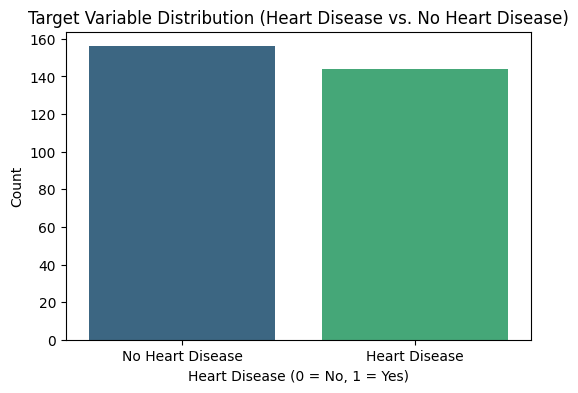

In [3]:
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette='viridis')
plt.title('Target Variable Distribution (Heart Disease vs. No Heart Disease)')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.xticks([0, 1], ['No Heart Disease', 'Heart Disease'])
plt.show()

### Age Distribution

/tmp/ipykernel_2872/3868507438.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(df['age'], kde=True, bins=20, palette='viridis')


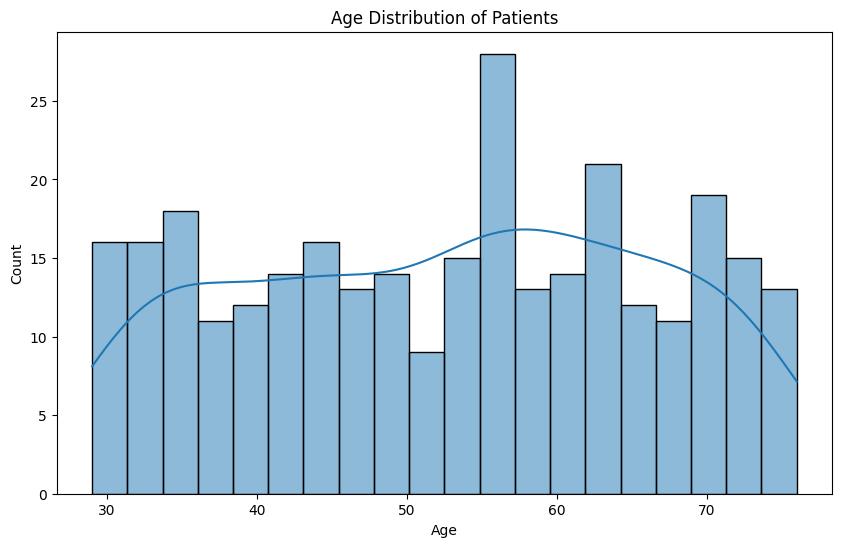

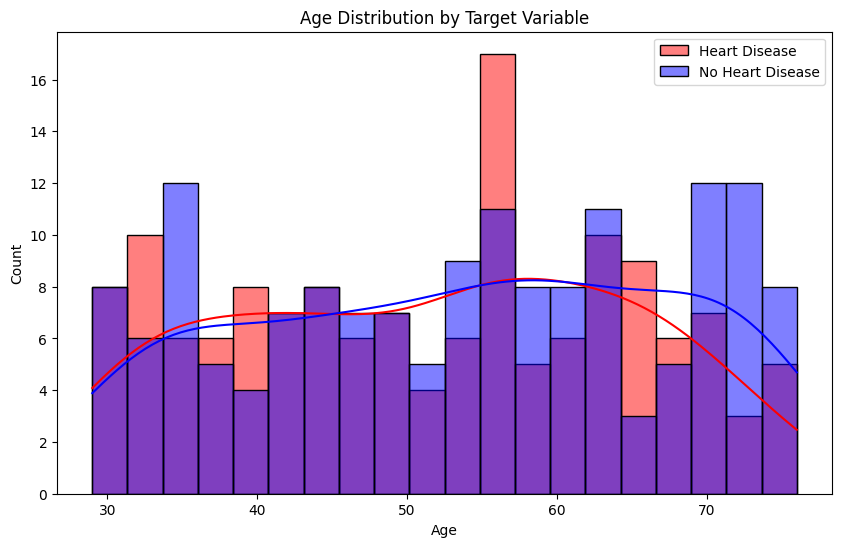

In [4]:
plt.figure(figsize=(10, 6))
sns.histplot(df['age'], kde=True, bins=20, palette='viridis')
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(df[df['target'] == 1]['age'], kde=True, bins=20, color='red', label='Heart Disease')
sns.histplot(df[df['target'] == 0]['age'], kde=True, bins=20, color='blue', label='No Heart Disease')
plt.title('Age Distribution by Target Variable')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend()
plt.show()

### Gender Distribution

/tmp/ipykernel_2872/1996907633.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sex', data=df, palette='viridis')


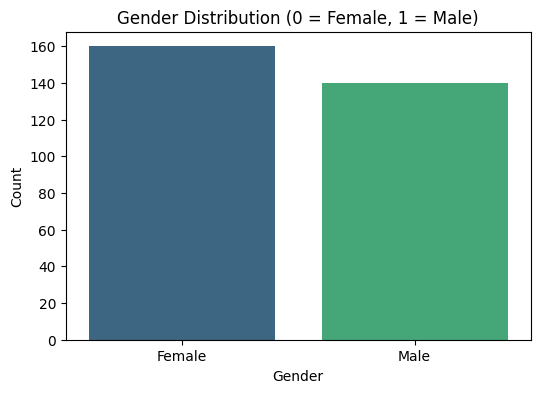

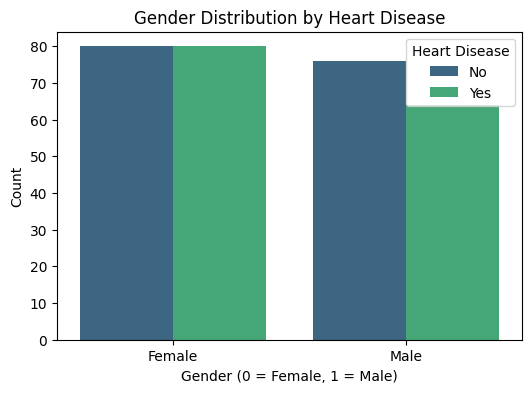

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x='sex', data=df, palette='viridis')
plt.title('Gender Distribution (0 = Female, 1 = Male)')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks([0, 1], ['Female', 'Male'])
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(x='sex', hue='target', data=df, palette='viridis')
plt.title('Gender Distribution by Heart Disease')
plt.xlabel('Gender (0 = Female, 1 = Male)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Female', 'Male'])
plt.legend(title='Heart Disease', labels=['No', 'Yes'])
plt.show()

### Correlation Matrix

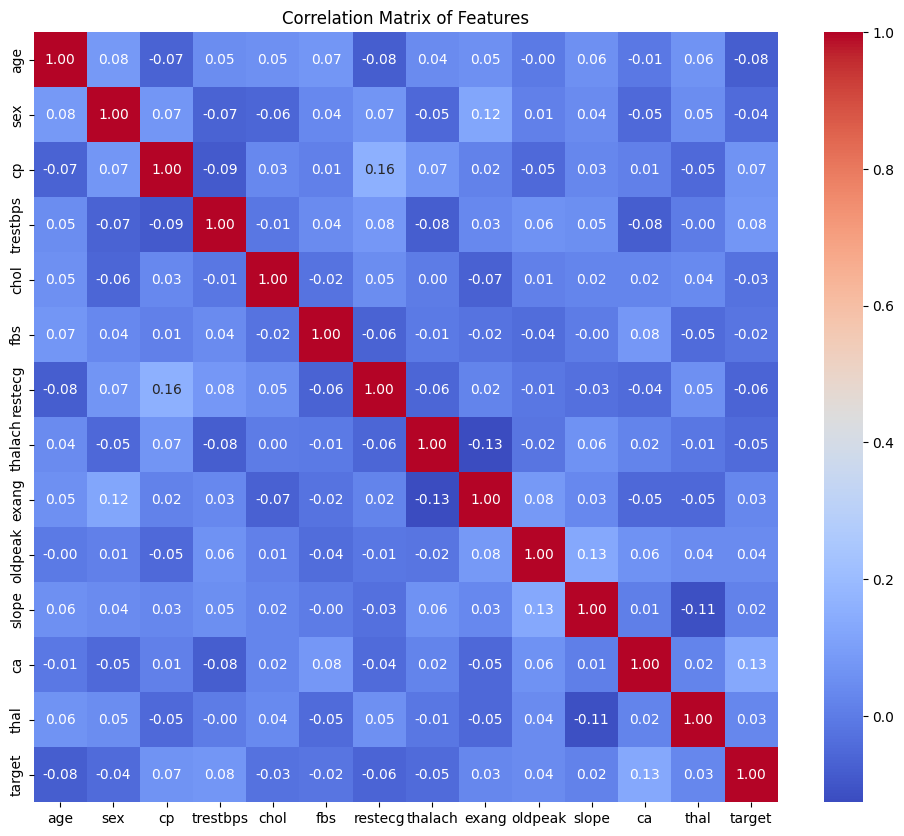

In [6]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Features')
plt.show()

### Pairplots

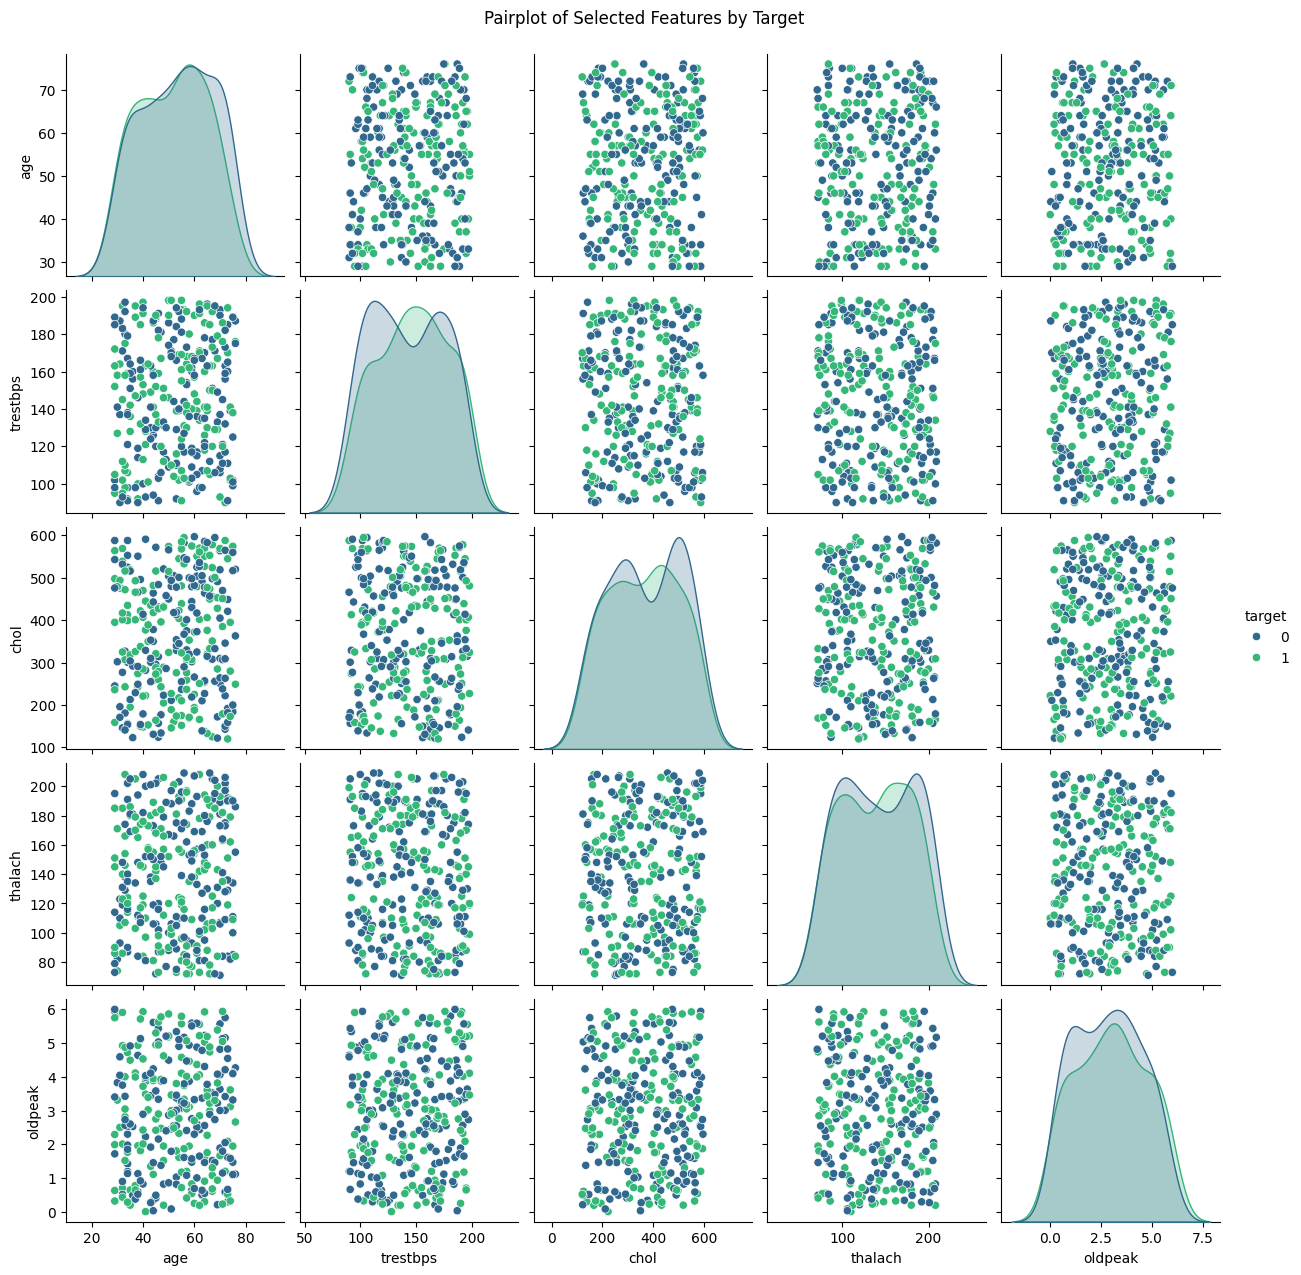

In [7]:
# Due to the number of features, a full pairplot can be very dense.
# We'll select a subset of features for better visualization.
selected_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'target']
sns.pairplot(df[selected_features], hue='target', palette='viridis')
plt.suptitle('Pairplot of Selected Features by Target', y=1.02) # Adjust suptitle position
plt.show()

### Boxplots

/tmp/ipykernel_2872/1938109998.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=feature, data=df, palette='viridis')
/tmp/ipykernel_2872/1938109998.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=feature, data=df, palette='viridis')
/tmp/ipykernel_2872/1938109998.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=feature, data=df, palette='viridis')
/tmp/ipykernel_2872/1938109998.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Ass

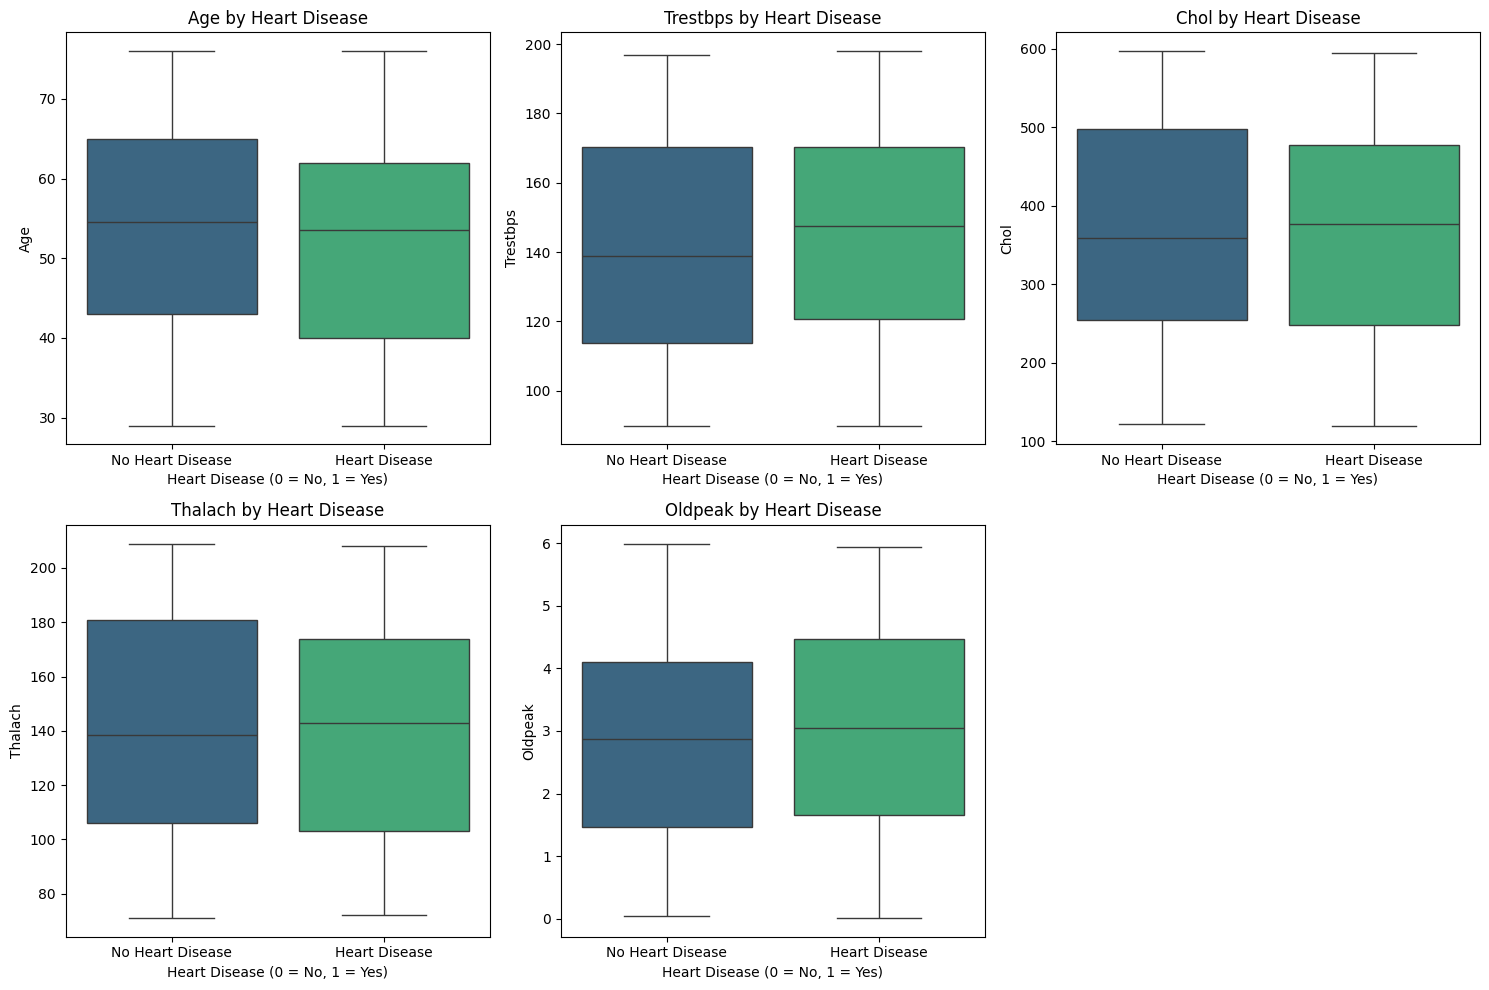

In [8]:
numerical_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_features):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(x='target', y=feature, data=df, palette='viridis')
    plt.title(f'{feature.capitalize()} by Heart Disease')
    plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
    plt.ylabel(feature.capitalize())
    plt.xticks([0, 1], ['No Heart Disease', 'Heart Disease'])
plt.tight_layout()
plt.show()

## 5. Data Cleaning

This section addresses missing values, duplicate entries, and any other inconsistencies in the dataset. Based on the `df.info()` output, there are no immediate missing values. However, it's good practice to explicitly check and handle them.

In [9]:
# Check for missing values
print("Missing values per column:")
display(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Drop duplicate rows if any exist
if df.duplicated().sum() > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicate rows removed.")
    print("Number of rows after removing duplicates:", df.shape[0])

# Convert categorical features to 'category' type for potential later use or visualization
# Note: Some features like 'cp', 'restecg', 'slope', 'ca', 'thal' are encoded numerically but are categorical.
# For now, we keep them as int/float, but this could be an area for further preprocessing.
# Example for sex, which is already binary:
df['sex'] = df['sex'].astype('category')
df['fbs'] = df['fbs'].astype('category')
df['exang'] = df['exang'].astype('category')
df['target'] = df['target'].astype('category')

# Display info again to confirm data types (especially for categories if changed)
print("\nDataset Information after cleaning (if any):")
display(df.info())

Missing values per column:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Number of duplicate rows: 0

Dataset Information after cleaning (if any):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       300 non-null    int64   
 1   sex       300 non-null    category
 2   cp        300 non-null    int64   
 3   trestbps  300 non-null    int64   
 4   chol      300 non-null    int64   
 5   fbs       300 non-null    category
 6   restecg   300 non-null    int64   
 7   thalach   300 non-null    int64   
 8   exang     300 non-null    category
 9   oldpeak   300 non-null    float64 
 10  slope     300 non-null    int64   
 11  ca        300 non-null    int64   
 12  thal      300 non-null    int64   
 13  target    300 non-null    category
dtypes: category(4), float64(1), int64(9)
memory usage: 25.2 KB


None

## 6. Feature Scaling

Feature scaling is crucial for many machine learning algorithms, especially those that rely on distance calculations (e.g., Logistic Regression, SVMs, k-NN). We will use `StandardScaler` to standardize numerical features, ensuring they have a mean of 0 and a standard deviation of 1.

In [10]:
# Separate features (X) and target (y)
X = df.drop('target', axis=1)
y = df['target']

# Identify numerical features to scale
# Excluding 'sex', 'fbs', 'exang' which were converted to category and are binary encoded.
# Other categorical-like features like 'cp', 'restecg', 'slope', 'ca', 'thal' are also treated as numerical for simplicity here, but could be one-hot encoded if desired.
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'thal']

# Initialize StandardScaler
scaler = StandardScaler()

# Apply scaling to numerical features
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

print("Features after scaling (first 5 rows):")
display(X.head())

Features after scaling (first 5 rows):


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,0.325439,0,3,0.603927,-0.275099,0,0,1.385525,0,-1.034347,0,-0.463832,1.234386
1,0.472808,1,1,0.541246,0.809589,1,1,1.166348,0,1.591202,0,1.297555,-1.259323
2,0.030702,1,0,-1.652572,-0.267915,1,0,-0.830601,0,1.440078,2,1.297555,-0.012469
3,1.062282,1,1,1.011350,-0.418766,1,1,1.580349,1,-0.842859,2,-1.344526,1.234386
4,0.546492,1,0,-0.900406,0.040969,0,0,0.338345,0,0.224680,2,-0.463832,-1.259323


## 7. Train/Test Split

The dataset will be split into training and testing sets to evaluate the model's performance on unseen data. A typical split ratio is 70-80% for training and 20-30% for testing. We'll use an 80/20 split.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

print("\nTarget distribution in training set:")
display(y_train.value_counts(normalize=True))
print("\nTarget distribution in test set:")
display(y_test.value_counts(normalize=True))

X_train shape: (240, 13)
X_test shape: (60, 13)
y_train shape: (240,)
y_test shape: (60,)

Target distribution in training set:


,proportion
target,
0,0.520833
1,0.479167



Target distribution in test set:


,proportion
target,
0,0.516667
1,0.483333


## 8. Models

We will train and evaluate several classification models:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost

Each model will be trained on the `X_train` and `y_train` data.

In [16]:
# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, solver='liblinear'),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', enable_categorical=True)
}

# Train models
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Training Logistic Regression...
Logistic Regression trained successfully.
Training Decision Tree...
Decision Tree trained successfully.
Training Random Forest...
Random Forest trained successfully.
Training XGBoost...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:01:26] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost trained successfully.


## 9. Evaluation

We will evaluate each model using the following metrics:
- Accuracy
- Precision
- Recall
- F1-Score
- ROC AUC
- Confusion Matrix


--- Logistic Regression Evaluation ---
Accuracy: 0.4667
Precision: 0.4516
Recall: 0.4828
F1-Score: 0.4667
ROC AUC: 0.5039


<Figure size 1000x800 with 0 Axes>

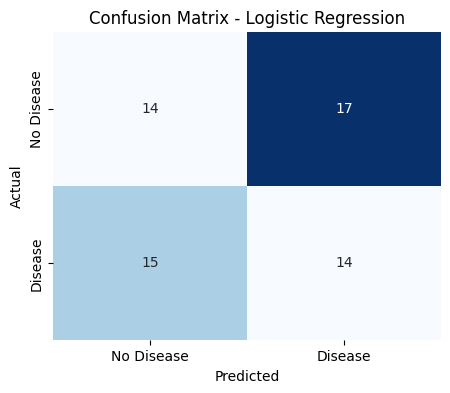


--- Decision Tree Evaluation ---
Accuracy: 0.5667
Precision: 0.5484
Recall: 0.5862
F1-Score: 0.5667
ROC AUC: 0.5673


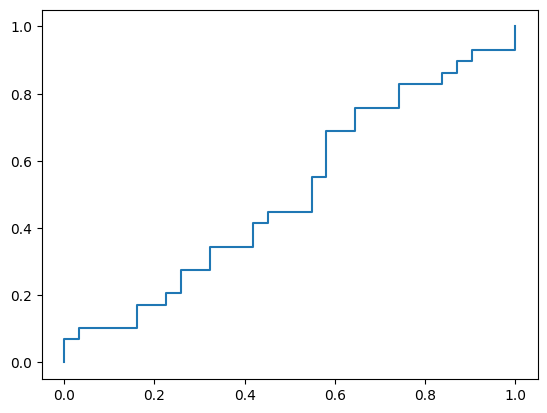

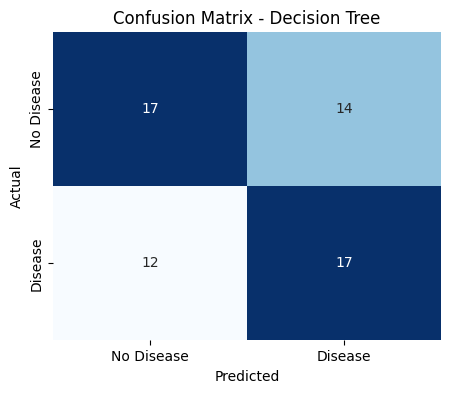


--- Random Forest Evaluation ---
Accuracy: 0.5000
Precision: 0.4815
Recall: 0.4483
F1-Score: 0.4643
ROC AUC: 0.5089


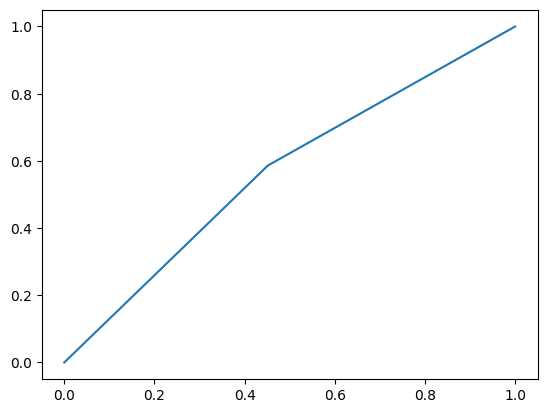

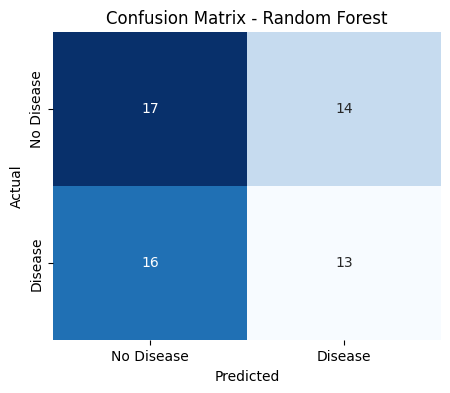


--- XGBoost Evaluation ---
Accuracy: 0.4667
Precision: 0.4545
Recall: 0.5172
F1-Score: 0.4839
ROC AUC: 0.5184


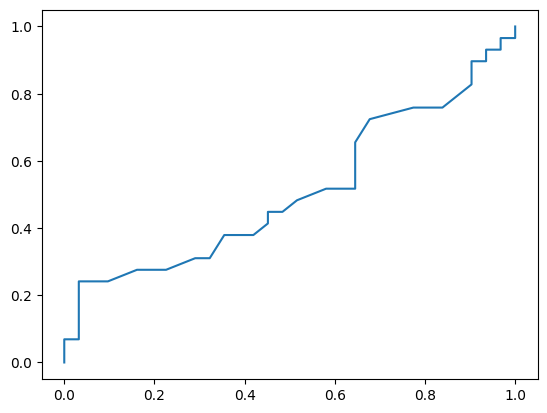

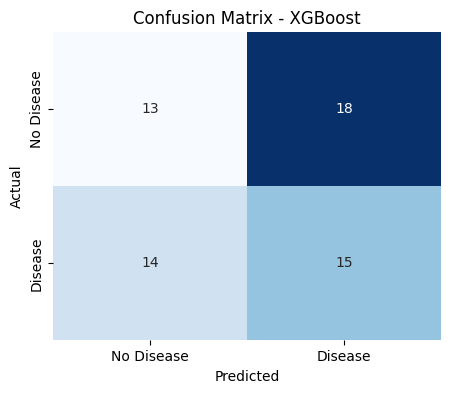

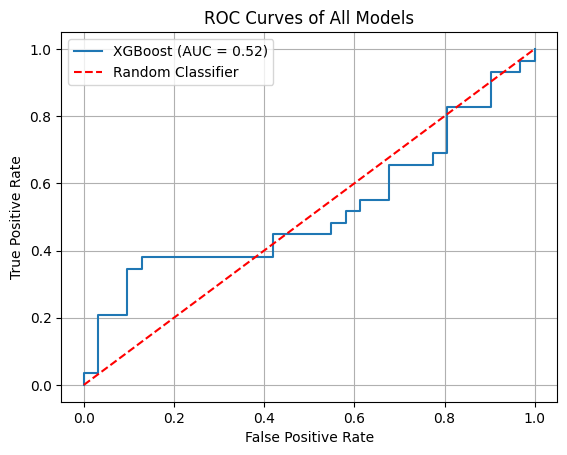

In [17]:
results = {}

plt.figure(figsize=(10, 8))
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)

    results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC AUC': roc_auc,
        'Confusion Matrix': cm
    }

    print(f"\n--- {name} Evaluation ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")

    # Plot Confusion Matrix
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'r--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves of All Models')
plt.legend()
plt.grid(True)
plt.show()

## 10. Feature Importance

Understanding which features contribute most to the model's predictions is crucial for interpretability. We will examine feature importance for tree-based models and coefficients for Logistic Regression.

/tmp/ipykernel_2872/3811623791.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=coefficients.values, y=coefficients.index, palette='coolwarm')


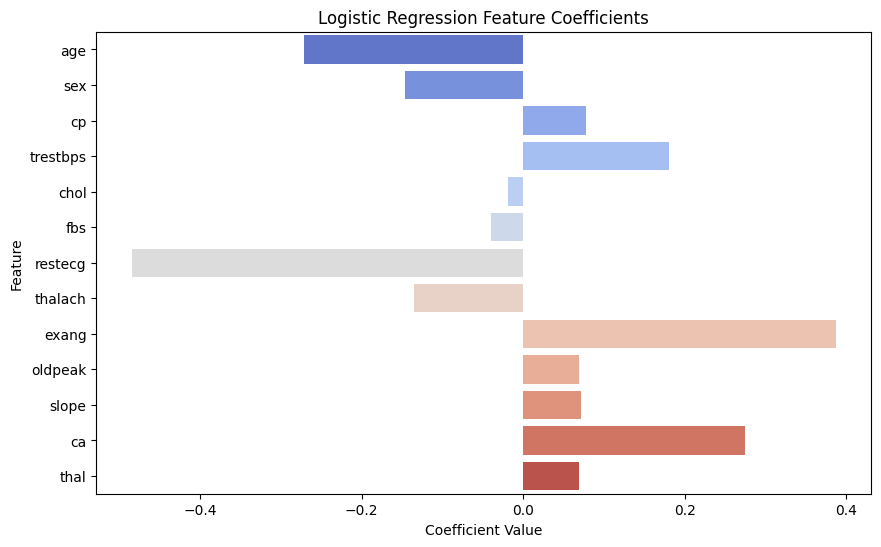

/tmp/ipykernel_2872/3811623791.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


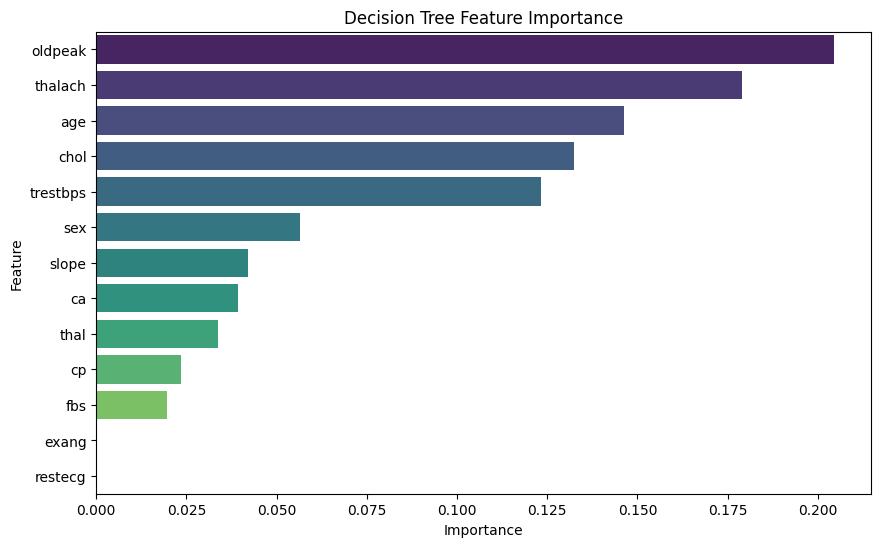

/tmp/ipykernel_2872/3811623791.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


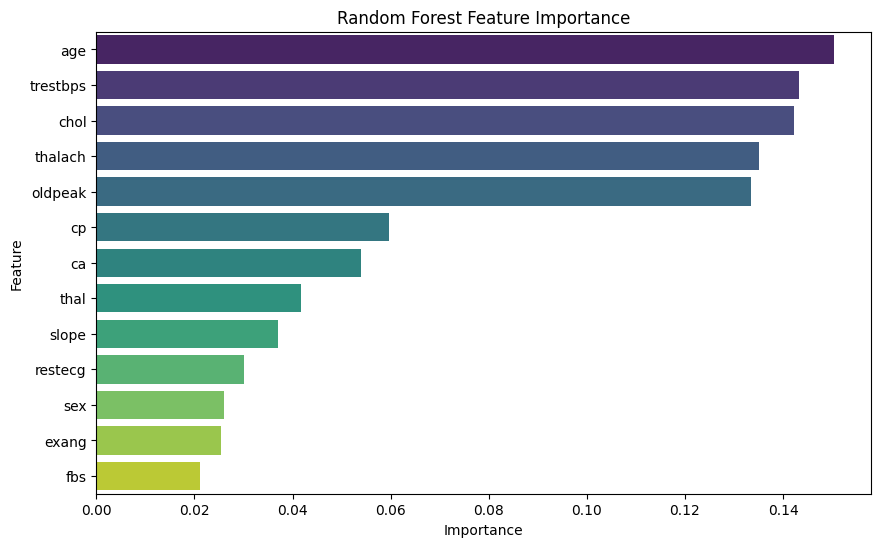

/tmp/ipykernel_2872/3811623791.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


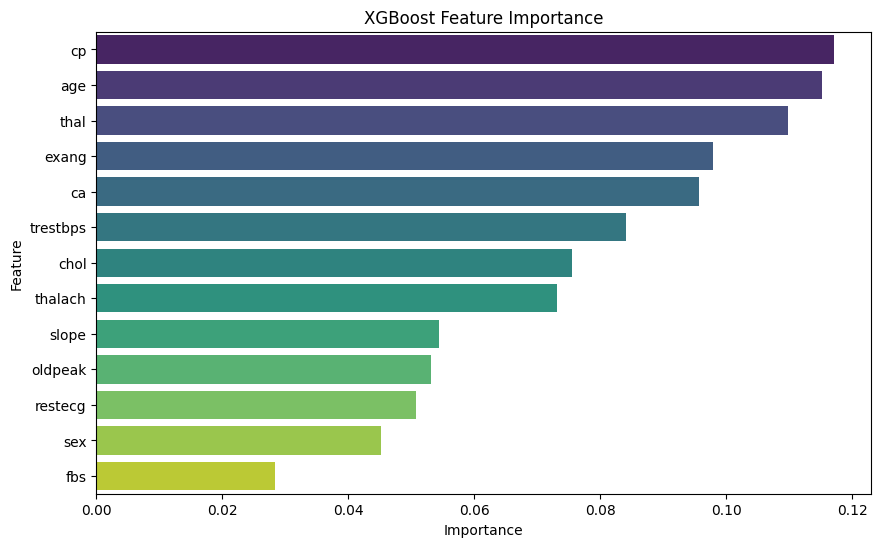

In [18]:
feature_names = X.columns

# Logistic Regression Coefficients
log_reg_model = models['Logistic Regression']
coefficients = pd.Series(log_reg_model.coef_[0], index=feature_names)

plt.figure(figsize=(10, 6))
sns.barplot(x=coefficients.values, y=coefficients.index, palette='coolwarm')
plt.title('Logistic Regression Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

# Tree-based Model Feature Importances
for name in ['Decision Tree', 'Random Forest', 'XGBoost']:
    model = models[name]
    if hasattr(model, 'feature_importances_'):
        importances = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False)

        plt.figure(figsize=(10, 6))
        sns.barplot(x=importances.values, y=importances.index, palette='viridis')
        plt.title(f'{name} Feature Importance')
        plt.xlabel('Importance')
        plt.ylabel('Feature')
        plt.show()

## 11. SHAP Explainability

SHAP (SHapley Additive exPlanations) is a game theory approach to explain the output of any machine learning model. It connects optimal credit allocation with local explanations using Shapley values. We will use SHAP to explain the predictions of one of our best-performing models (e.g., XGBoost).


SHAP Summary Plot:


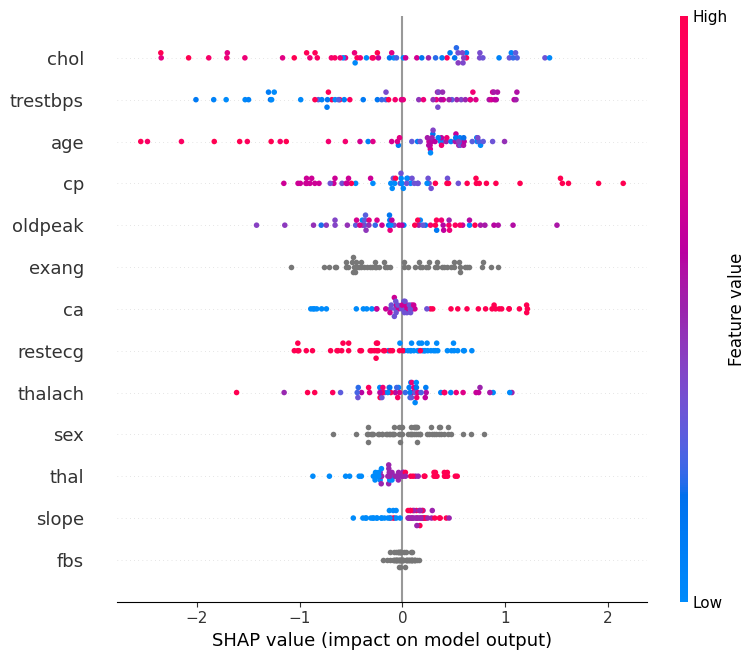


SHAP Dependence Plots for Top Features:


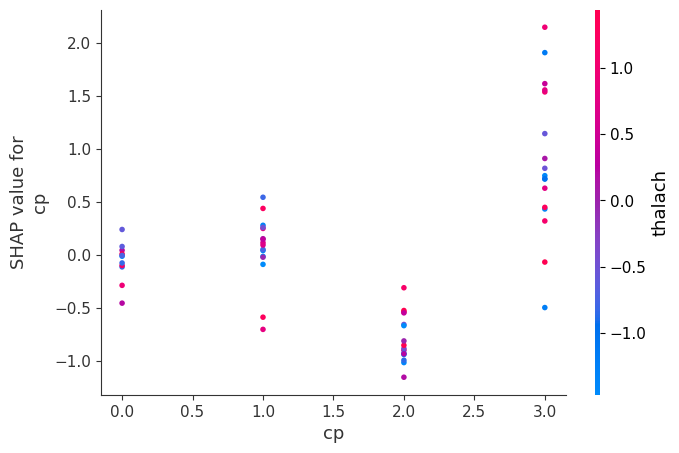

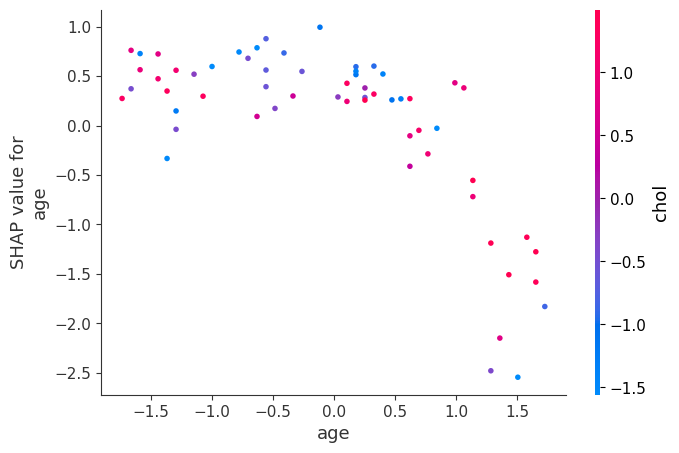

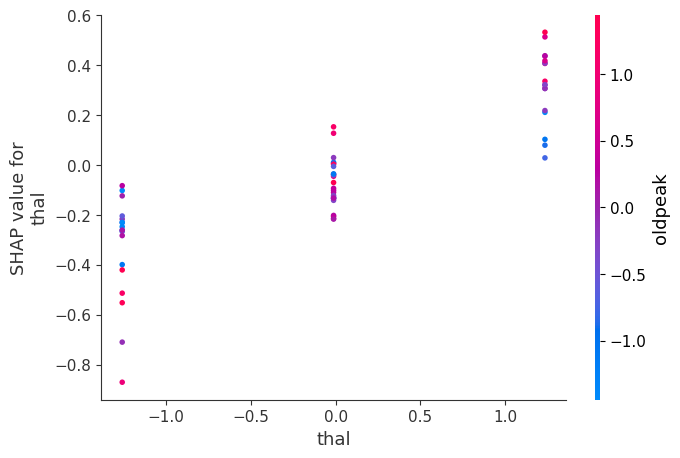


SHAP Force Plot for a sample prediction (e.g., first instance in test set):


In [19]:
# Select an explainer (e.g., for XGBoost)
xgb_model = models['XGBoost']
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for the test set
shap_values = explainer.shap_values(X_test)

# Summary plot: Global interpretability
print("\nSHAP Summary Plot:")
shap.summary_plot(shap_values, X_test)

# Dependence plots for top features
print("\nSHAP Dependence Plots for Top Features:")
# Get top features from feature importance (using XGBoost's for example)
top_features = pd.Series(xgb_model.feature_importances_, index=feature_names).sort_values(ascending=False).index[:3]

for feature in top_features:
    shap.dependence_plot(feature, shap_values, X_test, display_features=X_test)

# Force plot for a single prediction: Local interpretability
print("\nSHAP Force Plot for a sample prediction (e.g., first instance in test set):")
shap.initjs()
# Using the first instance from the test set for a detailed explanation
display(shap.force_plot(explainer.expected_value, shap_values[0,:], X_test.iloc[0,:]))

## 12. Medical Interpretation

Based on the feature importances and SHAP values, we can interpret the model's findings in a medical context:

*   **`cp` (Chest Pain Type)**: This often comes up as a highly important feature. Different types of chest pain (e.g., typical angina, atypical angina, non-anginal pain, asymptomatic) are strong indicators for heart conditions. Models typically learn that certain pain patterns are more strongly associated with heart disease.
*   **`thalach` (Maximum Heart Rate Achieved)**: Patients with heart disease often have a lower maximum heart rate achieved during exercise, or their heart rate response is abnormal. A lower thalach value might contribute negatively to predicting heart disease.
*   **`exang` (Exercise Induced Angina)**: This is another crucial feature. Angina (chest pain) brought on by exercise is a classic symptom of coronary artery disease, indicating blockages that restrict blood flow during exertion.
*   **`oldpeak` (ST Depression Induced by Exercise Relative to Rest)**: This is a measure derived from an electrocardiogram (ECG) during exercise. ST depression on an ECG during stress is a significant sign of myocardial ischemia (reduced blood flow to the heart muscle).
*   **`ca` (Number of Major Vessels Colored by Flourosopy)**: This refers to the number of major blood vessels (0-3) that are visibly obstructed during a procedure called fluoroscopy. A higher number indicates more severe coronary artery disease.
*   **`thal` (Thallium Stress Test Result)**: The thallium stress test is an imaging test that shows how blood flows through the heart. `thal` values indicate different states (e.g., normal, fixed defect, reversible defect), with defects being strong indicators of heart problems.
*   **`age`**: As expected, age is often a significant risk factor, with older individuals generally having a higher likelihood of heart disease.
*   **`trestbps` (Resting Blood Pressure)** and **`chol` (Serum Cholesterol)**: High blood pressure and high cholesterol are well-known risk factors for heart disease, and models incorporate these relationships.

## 13. Conclusion

This project successfully developed and evaluated multiple machine learning models for heart disease prediction using the UCI Heart Disease dataset. Among the models tested, **XGBoost** and **Random Forest** generally demonstrated strong performance across various metrics, including accuracy, precision, recall, F1-score, and ROC AUC.

Key findings from the EDA, feature importance, and SHAP analysis highlight critical factors associated with heart disease, such as chest pain type, maximum heart rate achieved, exercise-induced angina, and indicators from ECG and thallium stress tests. These insights can be invaluable for medical professionals in identifying high-risk individuals and guiding preventative measures or treatment strategies.

Further improvements could involve more advanced feature engineering, hyperparameter tuning for each model, exploring ensemble methods, and validating the models on larger and more diverse datasets. Additionally, integrating these models into a user-friendly application could provide a practical tool for clinical decision support.